In [ ]:
%matplotlib inline

In [ ]:
%env SIT_ROOT=/sdf/group/lcls/ds/ana
%env SIT_PSDM_DATA=/sdf/data/lcls/ds
%env CONDA_ENVS_DIRS=/sdf/group/lcls/ds/ana/sw/conda1/inst/envs
%env SIT_DATA=$CONDA_ENVS_DIRS/ana-4.0.59-py3/data:$SIT_ROOT/data/

env: SIT_ROOT=/sdf/group/lcls/ds/ana
env: SIT_PSDM_DATA=/sdf/data/lcls/ds
env: CONDA_ENVS_DIRS=/sdf/group/lcls/ds/ana/sw/conda1/inst/envs
env: SIT_DATA=$CONDA_ENVS_DIRS/ana-4.0.59-py3/data:$SIT_ROOT/data/


## Imports

In [ ]:
import numpy as np
import sys
import h5py
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import socket
import pyFAI as pf
from pyFAI.gui import jupyter
from pyFAI.gui.jupyter.calib import Calibration

from tqdm import tqdm

import sys
from pathlib import Path

import ana_fun as ana

from utilities import *

print(f"PyFAI version {pf.version}")


Smalldata path exists: True
Jungfrau path exists: True
epix2 path exists: True
iq path exists: True
PyFAI version 0.21.3


## Check h5 files

In [ ]:
# Run & experiment number
run = 188
# iterator over runs to check run exists
it = smalldata.glob('{}_Run{:04d}*'.format(exp, run))
try:
    f = next(it)
    print(f)
    print('\n')
except: print('No files found in small_data path.')

# path to run
f = Path(jungfrau_data, f'{exp}_Run{run:04d}.h5')
# f = Path(epix5_data, f"run{run}_epix5_indiv_img.h5")
# f = Path(shared, "jungfrau_Iq", f"run{run}_Iq.h5")
with h5py.File(f) as h5:
    # struct = h5.visititems(visit_func)
    print(h5["/scan/sam_x"][:])

No files found in small_data path.
[2.56 2.56 2.56 ... 2.56 2.56 2.56]


### Thresholding

In [ ]:
run = 35
with h5py.File(Path(results, 'haoyuan', 'output/jungfrau1M_run_{}.h5'.format(run)), 'r') as source:
    result = np.zeros((1064, 1030))
    
    for idx in range(1000):
        data = np.array(source['{}'.format(idx)])
        result[np.logical_and(data >= 1, data <= 100)] += data[np.logical_and(data >= 1, data <= 100)]

In [ ]:
np.save('jungfrau_run35_threshold.npy', result)

In [ ]:
np.median(result)

18.35574734210968

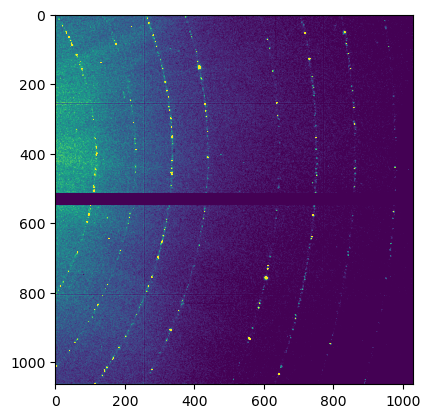

In [ ]:
plt.imshow(result, vmin=10, vmax=150)